# Functional programming


In [1]:
import numpy as np
import matplotlib.pyplot as plt

> ## Coding the solver
> We will first code the algorithm above by writing a `run_diffusion` function that takes all necessary arguments.
>
> **Task 1:**
>
> Complete the missing parts in the code below

In [2]:
def run_diffusion(
    L,       # length of the bar
    dx,      # discretization in space
    dt,      # discretization in time
    kappa,   # heat diffusivity
    T_init,  # initial temperature
    T_left,  # Temperature on the left
    h_right, # Flux on the right
    n_steps, # number of time steps
):
    assert kappa*dt/dx/dx<=0.5, 'Stability condition not satisfied'
    
    # spatial discretization
    x = np.arange(0, L+dx, dx)
    nx = len(x)

    # solution vectors
    T = np.zeros((n_steps,nx))

    # temperature field at t=0
    T[0,:] = T_init

    # loop through time
    for n in range(n_steps-1):
        # solution on the left
        T[n+1,0] = T_left

        # solution in the interior
        for m in range(1,nx-1):
            T[n+1, m] = T[n,m] + kappa * dt / dx**2 * (T[n,m+1] - 2 * T[n,m] + T[n,m-1])

        # solution on the right
        T[n+1,-1] = T[n,-1] + 2 * kappa * dt / dx**2 * (T[n,-2] - T[n,-1] + h_right * dx)

    return x, T

> ## Running the code
> Now let us use the code to run a simple diffusion example.
>
> **Task 2:**
>
> Run the code for the following case:
>
> - **Domain and discretization**: $L=1$, $\Delta x = 0.1$, $\Delta t = 0.001$
>
> - **PDE parameters**: $\kappa=1$
>
> - **Initial and boundary conditions**: $T_\mathrm{init}=25$, $T_\mathrm{left}=100$, $h_\mathrm{right}=0$
>
> - **Solver parameters**: Run for 1000 time steps
>
> After running, plot your solution over $x$ at time steps 0, 10, 100 and 999 together on the same plot

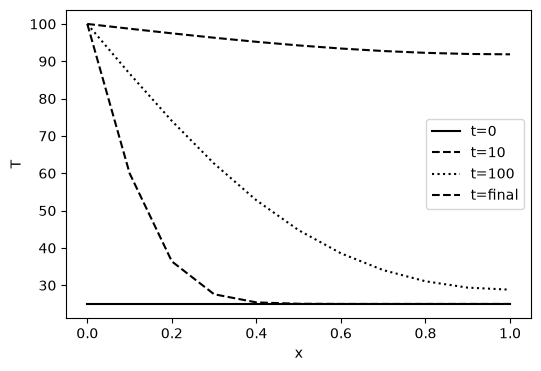

In [7]:
# run the solver
x,T = run_diffusion(
    1,       # length of the bar
    0.1,      # discretization in space
    0.001,      # discretization in time
    1,   # heat diffusivity
    25,  # initial temperature
    100,  # Temperature on the left
    0, # Flux on the right
    1000, # number of time steps
)

# plot the solution
f, ax = plt.subplots(figsize=(6,4))
ax.plot(x,T[0,:], 'k-', label='t=0')
ax.plot(x,T[10,:], 'k--', label='t=10')
ax.plot(x,T[100,:], 'k:', label='t=100')
ax.plot(x,T[-1,:], 'k--', label='t=final')
ax.set_xlabel('x')
ax.set_ylabel('T')
ax.legend()

> See how even though the parameters can be neatly organized into the four logical groups above? Nevertheless, **they all get jammed together in the same function call** and the best we can do is to order them in some sensible way.
>
> **Task 3:**
>
> Repeat the same example from before but set $\kappa=5$

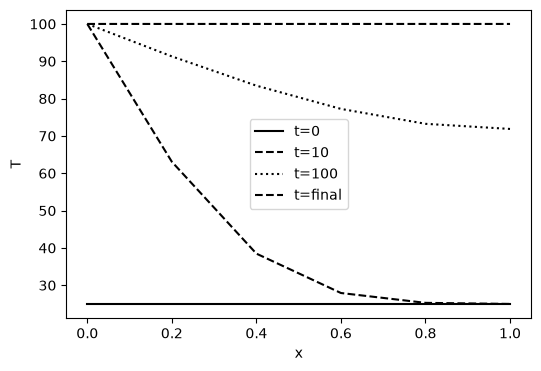

In [8]:
# run the solver
x,T = run_diffusion(
    1,       # length of the bar
    0.1,      # discretization in space
    0.001,      # discretization in time
    5,   # heat diffusivity
    25,  # initial temperature
    100,  # Temperature on the left
    0, # Flux on the right
    1000, # number of time steps
)

# plot the solution
f, ax = plt.subplots(figsize=(6,4))
ax.plot(x,T[0,:], 'k-', label='t=0')
ax.plot(x,T[10,:], 'k--', label='t=10')
ax.plot(x,T[100,:], 'k:', label='t=100')
ax.plot(x,T[-1,:], 'k--', label='t=final')
ax.set_xlabel('x')
ax.set_ylabel('T')
ax.legend()

> Did you notice how to **change only one parameter** you had to repeat all the others? This is common in the functional programming paradigm: without global variables, functions calls tend to involve a large number of arguments and make the code look a bit clunky. It also involves a risk: maybe when copy/pasting you change some other parameter by mistake that you did not want to touch.
>
> Also notice how you had to do the plotting manually again. You could have implemented a dedicated plotting function, but even then you would need to keep passing `x` and `T` between functions. Not very clean.
>
> ## Extending the solver
>
> For the final task of this part, the goal is to code a modified version of the solver in which we do not apply a flux BC on the right but **another fixed temperature** $T_\mathrm{right}$. One possible way to do this is to add an `if` statement in the original code, but the function would then need **yet another argument** to inform it that the BC is now a fixed temperature and not a flux, otherwise it would have no way to discern that just from the value of the argument. Instead let us just code the whole thing again with a different name.
>
> **Task 4:**
>
> Complete the missing parts in the code below

In [9]:
def run_diffusion_two(
    L,       # length of the bar
    dx,      # discretization in space
    dt,      # discretization in time
    kappa,   # heat diffusivity
    T_init,  # initial temperature
    T_left,  # Temperature on the left
    T_right, # Temperature on the right
    n_steps, # number of time steps
):
    assert kappa*dt/dx/dx<=0.5, 'Stability condition not satisfied'
    
    # spatial discretization
    x = np.arange(0, L+dx, dx)
    nx = len(x)

    # solution vectors
    T = np.zeros((n_steps,nx))

    # temperature field at t=0
    T[0,:] = T_init

    # loop through time
    for n in range(n_steps-1):
        # solution on the left
        T[n+1,0] = T_left

        # solution in the interior
        for m in range(1,nx-1):
            T[n+1, m] = T[n,m] + kappa * dt / dx**2 * (T[n,m+1] - 2 * T[n,m] + T[n,m-1])

        # solution on the right
        T[n+1,-1] = T_right

    return x, T

> Let us now try it out.
>
> **Task 5:**
>
> Run the new solver with the same parameter set of the first example ($\kappa=1$) but now with $T_\mathrm{right}=50$

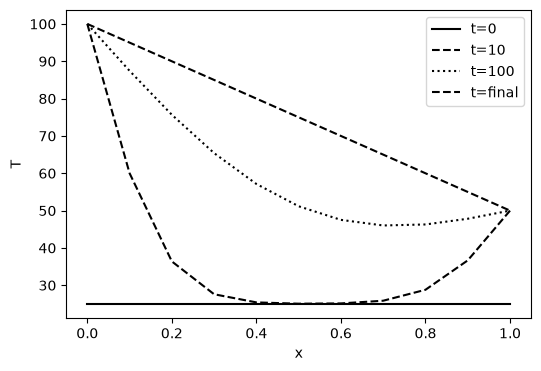

In [ ]:
# run the solver
x,T = run_diffusion_two(
    1,       # length of the bar
    0.1,      # discretization in space
    0.001,      # discretization in time
    1,   # heat diffusivity
    25,  # initial temperature
    100,  # Temperature on the left
    50, # Temperature on the right
    1000, # number of time steps
)

# plot the solution
f, ax = plt.subplots(figsize=(6,4))
ax.plot(x,T[0,:], 'k-', label='t=0')
ax.plot(x,T[10,:], 'k--', label='t=10')
ax.plot(x,T[100,:], 'k:', label='t=100')
ax.plot(x,T[-1,:], 'k--', label='t=final')
ax.set_xlabel('x')
ax.set_ylabel('T')
ax.legend()

Notice **how much code we had to repeat** in order to make such a small change. This is another drawback of functional programming: extending existing code often involves either a lot of repeated code or a convoluted set of `if-then-else` statements coupled with even more function arguments.

> By Iuri Rocha and Marcel Zijlema, Delft University of Technology. CC BY 4.0, more info [on the Credits page of Workbook](https://mude.citg.tudelft.nl/workbook-2025/credits.html).